# 생성형 AI를 활용한 제조결함 데이터 생성 실습

EPFL-IMOS의 [AnomalyAny](https://github.com/EPFL-IMOS/AnomalyAny)를 이용합니다.
VS Code의 Colab **GPU 커널을 다시 시작한 뒤** 위에서 아래로 모두 실행하세요.
원본의 200단계, table 1장·hazelnut 4장·PCB 4장 생성을 유지합니다.
PCB 입력 이미지는 이 노트북에 포함되어 있습니다. 결과는 원격 작업 폴더의 `lab_results/`에도 저장됩니다.
원본과 같은 float32 계산을 사용합니다. A100 등 GPU 메모리가 40GB 이상인 환경을 권장합니다.
설치한 패키지와 실습 코드가 섞이지 않도록 새 GPU 커널에서 시작하세요.

**실행 검증 완료:** A100 80GB에서 모든 코드 셀을 순서대로 실행했으며, 테이블 1장·헤이즐넛 4장·PCB 4장과 attention 시각화를 확인했습니다.


In [1]:
import sys, subprocess, importlib.metadata as metadata, importlib.util
import torch

if not torch.cuda.is_available():
    raise RuntimeError("Colab GPU 커널을 선택한 다음 다시 실행하세요. 이 실습은 CUDA GPU가 필요합니다.")
print("Python:", sys.version.split()[0])
print("GPU:", torch.cuda.get_device_name(0))
print("GPU 총 메모리(GiB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))
print("GPU 남은 메모리(GiB):", round(torch.cuda.mem_get_info()[0] / 2**30, 2))

# 실제 검증에 사용한 라이브러리 버전. Colab의 CUDA용 torch/torchvision은 유지합니다.
required = {
    "diffusers": "0.33.1", "transformers": "4.52.4",
    "huggingface-hub": "0.36.2", "accelerate": "1.15.0", "pyrallis": "0.3.1",
}
to_install = []
for package, wanted in required.items():
    try:
        installed = metadata.version(package)
    except metadata.PackageNotFoundError:
        installed = None
    if installed != wanted:
        to_install.append(f"{package}=={wanted}")
if to_install:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *to_install])
try:
    clip_installed = metadata.version("clip") == "1.0"
except metadata.PackageNotFoundError:
    clip_installed = False
if not clip_installed:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/openai/CLIP.git"])
import clip, pyrallis
assert callable(clip.load) and callable(clip.tokenize), "OpenAI CLIP 설치를 확인하세요."
print("설치 확인 완료:", {p: metadata.version(p) for p in required})
print("OpenAI CLIP:", metadata.version("clip"))


Python: 3.13.15
GPU: NVIDIA A100-SXM4-80GB
GPU 총 메모리(GiB): 79.25
GPU 남은 메모리(GiB): 78.42
설치 확인 완료: {'diffusers': '0.33.1', 'transformers': '4.52.4', 'huggingface-hub': '0.36.2', 'accelerate': '1.15.0', 'pyrallis': '0.3.1'}
OpenAI CLIP: 1.0


In [ ]:
from pathlib import Path
import os

WORK_ROOT = Path("/content/anomalyany_lab") if Path("/content").is_dir() else Path.cwd() / "anomalyany_lab"
WORK_ROOT.mkdir(parents=True, exist_ok=True)
REPO = WORK_ROOT / "AnomalyAny"
REPO_REVISION = "585198d594582f41442a779dd2f91288066092e7"
if not (REPO / ".git").exists():
    subprocess.check_call(["git", "clone", "https://github.com/EPFL-IMOS/AnomalyAny.git", str(REPO)])
    subprocess.check_call(["git", "-C", str(REPO), "checkout", REPO_REVISION])
actual_revision = subprocess.check_output(["git", "-C", str(REPO), "rev-parse", "HEAD"], text=True).strip()
assert actual_revision == REPO_REVISION, "실습 저장소 버전이 다릅니다. 별도의 새 실습 폴더를 사용하세요."
print("AnomalyAny commit:", actual_revision)
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
RESULTS = WORK_ROOT / "lab_results"
RESULTS.mkdir(exist_ok=True)
print("현재 작업 폴더:", REPO)


AnomalyAny commit: 585198d594582f41442a779dd2f91288066092e7
현재 작업 폴더: /content/anomalyany_lab/AnomalyAny


다음 접힌 셀에는 제공하신 PCB 정상 이미지가 들어 있습니다. 그대로 실행하면 입력 파일을 준비합니다.

In [3]:
import base64, hashlib
PCB_IMAGE_PATH = WORK_ROOT / "normal.png"
_pcb_bytes = base64.b64decode('...')
assert hashlib.sha256(_pcb_bytes).hexdigest() == 'cf5ed3e53ae50264a7c658e5d5ed6e5d7507a5931eb4c6589d6abbbc2a130009'
PCB_IMAGE_PATH.write_bytes(_pcb_bytes)
del _pcb_bytes
print("PCB 이미지 준비:", PCB_IMAGE_PATH.name)


PCB 이미지 준비: normal.png


In [4]:
# 학습하지 않는 CLIP 가중치의 기울기 저장을 막습니다.
# 원본 파일은 별도 실습 저장소에만 보존하며, 재실행해도 같은 패치가 적용됩니다.
def patch_source(relative_path, replacements):
    path = REPO / relative_path
    backup = path.with_suffix(path.suffix + ".lab_original")
    if not backup.exists():
        backup.write_bytes(path.read_bytes())
    text = backup.read_text(encoding="utf-8")
    for before, after in replacements:
        if before not in text:
            raise RuntimeError(f"원본 코드가 변경되었습니다: {relative_path}: {before[:70]}")
        text = text.replace(before, after)
    compile(text, str(path), "exec")
    path.write_text(text, encoding="utf-8")

patch_source("clip_pipeline_attend_and_excite.py", [
    ("        model.train()", "        model.requires_grad_(False).eval()"),
    ("self.unet.in_channels", "self.unet.config.in_channels"),
    ("noise = torch.randn(latents.shape, generator=generator, device='cuda')", "noise = torch.randn(latents.shape, generator=generator, device=latents.device, dtype=prompt_embeds.dtype)"),
    ("image = self.vae.decode(latents, return_dict=False)[0]", "image = self.vae.decode(latents.to(dtype=self.vae.dtype), return_dict=False)[0]"),
    ("criterion_cosine(delta_1, delta_2).mean()", "criterion_cosine(delta_1.float(), delta_2.float()).mean()"),
    ("criterion_cosine(prompt_embeds, prompt_embeds_original).mean()", "criterion_cosine(prompt_embeds.float(), prompt_embeds_original.float()).mean()"),
    ("        # print()\n        latents = latents - step_size * grad_cond", "        if not torch.isfinite(grad_cond).all():\n            raise RuntimeError('최적화 기울기에 NaN/Inf가 발생했습니다.')\n        latents = latents - step_size * grad_cond"),
    ("with self.progress_bar(total=num_inference_steps)", "with self.progress_bar(total=len(timesteps))"),
    ("                for i, t in enumerate(timesteps):", "                for i, t in enumerate(timesteps):\n                    if i % 10 == 0:\n                        print(f'이미지 생성 진행: {i}/{len(timesteps)}', flush=True)"),
])
print("실습 코드 준비 완료")


실습 코드 준비 완료


In [5]:
from typing import List, Dict
import torch

import sys 



from clip_pipeline_attend_and_excite import RelationalAttendAndExcitePipeline
from config import RunConfig
from run import run_on_prompt, get_indices_to_alter, run_on_prompt_and_image, run_on_prompt_and_masked_image
from utils import vis_utils
from utils.ptp_utils import AttentionStore, show_cross_attention_binary

from utils.vis_utils import vis_ann

from PIL import Image

device = torch.device("cuda")

 

from IPython.display import display
import numpy as np
import gc, time
print("실습 모듈 import 완료")


실습 모듈 import 완료


In [6]:
NUM_DIFFUSION_STEPS = 200
GUIDANCE_SCALE = 12.5
MAX_NUM_WORDS = 77
MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
stable = RelationalAttendAndExcitePipeline.from_pretrained(
    MODEL_ID, safety_checker=None, torch_dtype=torch.float32,
).to(device)
for component in (stable.unet, stable.vae, stable.text_encoder):
    component.requires_grad_(False)
tokenizer = stable.tokenizer
print("Stable Diffusion 모델 로딩 완료:", MODEL_ID)

def token_indices_for_word(prompt, target):
    prompt_ids = tokenizer(prompt)["input_ids"]
    target_ids = tokenizer(target, add_special_tokens=False)["input_ids"]
    positions = [i for i in range(1, len(prompt_ids) - len(target_ids))
                 if prompt_ids[i:i + len(target_ids)] == target_ids]
    if len(positions) != 1:
        raise ValueError(f"결함 단어의 토큰을 하나로 특정할 수 없습니다: {target}")
    indices = list(range(positions[0], positions[0] + len(target_ids)))
    print("프롬프트 토큰:", {i: tokenizer.decode([t]) for i, t in enumerate(prompt_ids)})
    print("결함 토큰:", {i: tokenizer.decode([prompt_ids[i]]) for i in indices})
    return ",".join(map(str, indices))

for _prompt, _word in [
    ("a photo of a table that is faded", "faded"),
    ("a photo of a hazelnut with a crack on it", "crack"),
    ("a photo of a pcb with a crack on it", "crack"),
]:
    token_indices_for_word(_prompt, _word)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'clip_pipeline_attend_and_excite.RelationalAttendAndExcitePipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Stable Diffusion 모델 로딩 완료: stable-diffusion-v1-5/stable-diffusion-v1-5
프롬프트 토큰: {0: '<|startoftext|>', 1: 'a', 2: 'photo', 3: 'of', 4: 'a', 5: 'table', 6: 'that', 7: 'is', 8: 'faded', 9: '<|endoftext|>'}
결함 토큰: {8: 'faded'}
프롬프트 토큰: {0: '<|startoftext|>', 1: 'a', 2: 'photo', 3: 'of', 4: 'a', 5: 'hazelnut', 6: 'with', 7: 'a', 8: 'crack', 9: 'on', 10: 'it', 11: '<|endoftext|>'}
결함 토큰: {8: 'crack'}
프롬프트 토큰: {0: '<|startoftext|>', 1: 'a', 2: 'photo', 3: 'of', 4: 'a', 5: 'pcb', 6: 'with', 7: 'a', 8: 'crack', 9: 'on', 10: 'it', 11: '<|endoftext|>'}
결함 토큰: {8: 'crack'}


In [ ]:
def run_and_display(prompts: List[str],
                    controller: AttentionStore,
                    indices_to_alter: List[int],
                    init_image: Image.Image,
                    init_image_guidance_scale: float,
                    mask_image: str,
                    generator: torch.Generator,
                    run_standard_sd: bool = False,
                    scale_factor: int = 20,
                    thresholds: Dict[int, float] = {0: 0.05, 10: 0.5, 20: 0.8},
                    max_iter_to_alter: int = 25,
                    display_output: bool = False,
                    normal_prompt=None,
                    detailed_prompt=None):
    assert normal_prompt and detailed_prompt
    config = RunConfig(prompt=prompts[0],
                       run_standard_sd=run_standard_sd,
                       scale_factor=scale_factor,
                       thresholds=thresholds,
                       max_iter_to_alter=max_iter_to_alter,
                       n_inference_steps=NUM_DIFFUSION_STEPS,
                       guidance_scale=GUIDANCE_SCALE)
    image, image_latent = run_on_prompt_and_masked_image(model=stable,
                          prompt=prompts,
                          controller=controller,
                          token_indices=indices_to_alter,
                          init_image=init_image,
                          init_image_guidance_scale=init_image_guidance_scale,
                          mask_image=mask_image,
                          seed=generator,
                          config=config,
                          normal_prompt=normal_prompt,
                          detailed_prompt=detailed_prompt)
    if not torch.isfinite(image_latent).all():
        raise RuntimeError("이미지 생성 중 NaN/Inf가 발생했습니다.")
    assert controller.cur_att_layer == 0, "Attention 계층 카운터가 일치하지 않습니다."
    cross_maps = [m for key, maps in controller.attention_store.items() if key.endswith("_cross") for m in maps]
    assert cross_maps and all(torch.isfinite(m).all() for m in cross_maps), "Attention 지도를 확인하세요."
    if display_output:
        display(image)
    return image, image_latent

## 1. 테이블 변색 결함

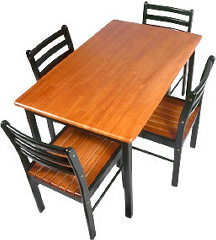

프롬프트 토큰: {0: '<|startoftext|>', 1: 'a', 2: 'photo', 3: 'of', 4: 'a', 5: 'table', 6: 'that', 7: 'is', 8: 'faded', 9: '<|endoftext|>'}
결함 토큰: {8: 'faded'}


In [8]:
from PIL import Image

object_name = "table"
prompt = f"a photo of a {object_name} that is faded"
normal_prompt = f"a photo of a {object_name}"
detailed_prompt = f"a photo of a {object_name} with areas of discoloration or lightening due to prolonged sun exposure"

root_path = str(REPO / "example_web") + "/"
image_guidance_path = root_path + "table.jpg"


image_guidance = Image.open(image_guidance_path).convert("RGB")
original_size = image_guidance.size
image_guidance.thumbnail((768, 768))
display(image_guidance)
tokens = token_indices_for_word(prompt, 'faded')


{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'table',
 6: 'that',
 7: 'is',
 8: 'faded'}
Altering tokens: ['faded']
table: 1/1 생성 시작 (seed=42)


  0%|          | 0/61 [00:00<?, ?it/s]

이미지 생성 진행: 0/61
이미지 생성 진행: 10/61
이미지 생성 진행: 20/61
이미지 생성 진행: 30/61
이미지 생성 진행: 40/61
이미지 생성 진행: 50/61
이미지 생성 진행: 60/61


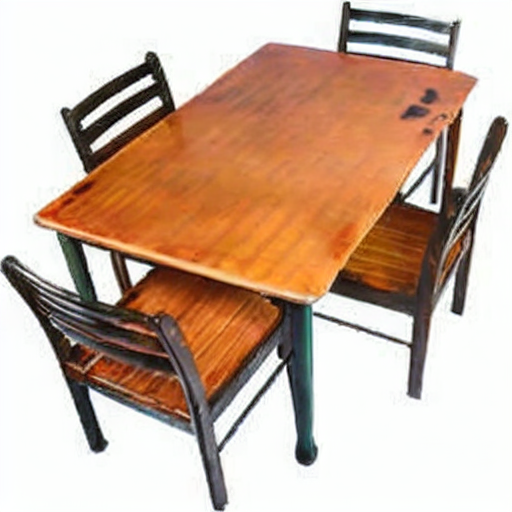

table: 생성 완료, 187.6초


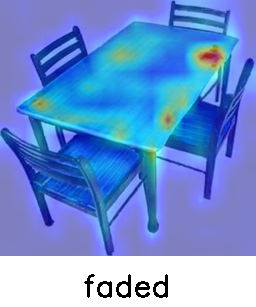

이미지 생성 셀 완료. 소요 시간(초): [187.6]


In [9]:
import random
from run import get_indices_to_alter_new
import time

seeds = [42]

token_indices = get_indices_to_alter_new(stable, prompt, tokens)


compute_time = []
for sample_number, seed in enumerate(seeds, 1):
    print(f"table: {sample_number}/{len(seeds)} 생성 시작 (seed={seed})", flush=True)
    g = torch.Generator(device=device).manual_seed(seed)
    prompts = [prompt]
    controller = AttentionStore()

    start_time = time.time()
    image, image_latent = run_and_display(prompts=prompts,
                            controller=controller,
                            indices_to_alter=token_indices,
                            # init_image=None,
                            init_image=image_guidance,
                            init_image_guidance_scale=0.3,
                            mask_image=None,   
                            generator=g,
                            run_standard_sd=False,
                            display_output=True,
                            scale_factor=50,
                            normal_prompt=normal_prompt,
                            detailed_prompt=detailed_prompt,)
    # print("--- %s seconds ---" % (time.time() - start_time))
    elapsed = time.time() - start_time
    compute_time.append(elapsed)
    image.save(RESULTS / f"table_{seed}.png")
    print(f"table: 생성 완료, {elapsed:.1f}초", flush=True)
    
    attention_images=vis_utils.show_cross_attention(attention_store=controller,
                                   prompt=prompt,
                                   tokenizer=tokenizer,
                                   res=16,
                                   from_where=("up", "down", "mid"),
                                   indices_to_alter=token_indices,
                                   orig_image=image)

    del image_latent
    gc.collect()
    torch.cuda.empty_cache()
print("이미지 생성 셀 완료. 소요 시간(초):", [round(t, 1) for t in compute_time])


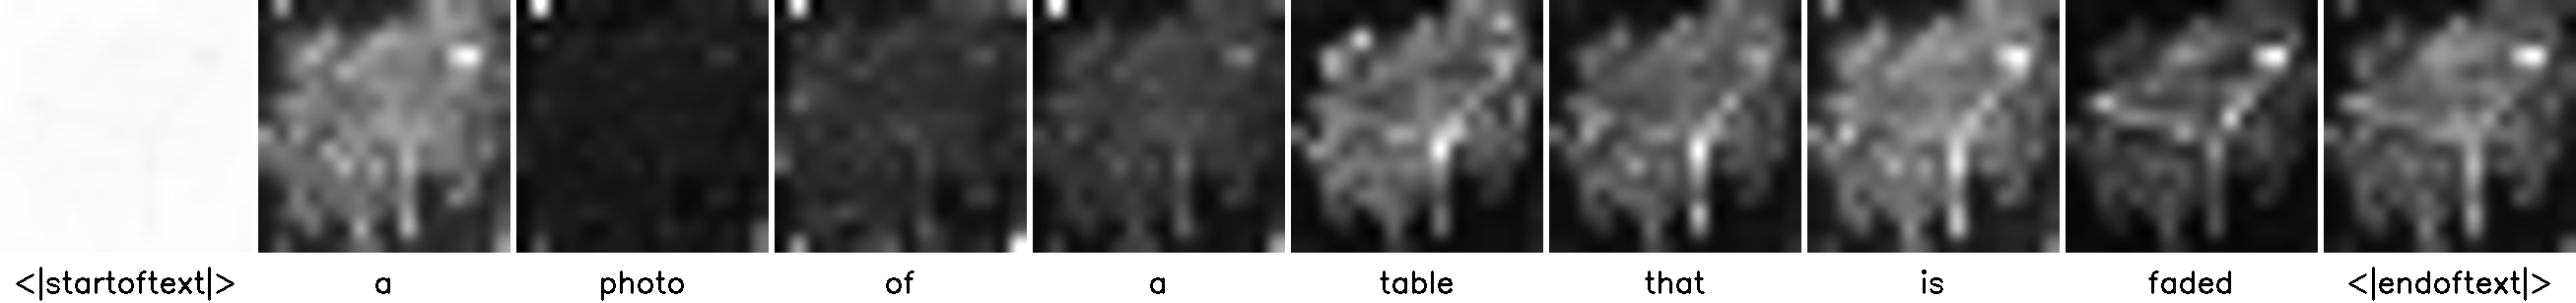

테이블 이진 attention 시각화 완료


In [10]:
images, attention_maps = show_cross_attention_binary(controller, tokenizer, prompts, res=16, from_where=("up", "mid", "down"))
assert images is not None and attention_maps is not None
print("테이블 이진 attention 시각화 완료")


## 2. 헤이즐넛 균열 결함

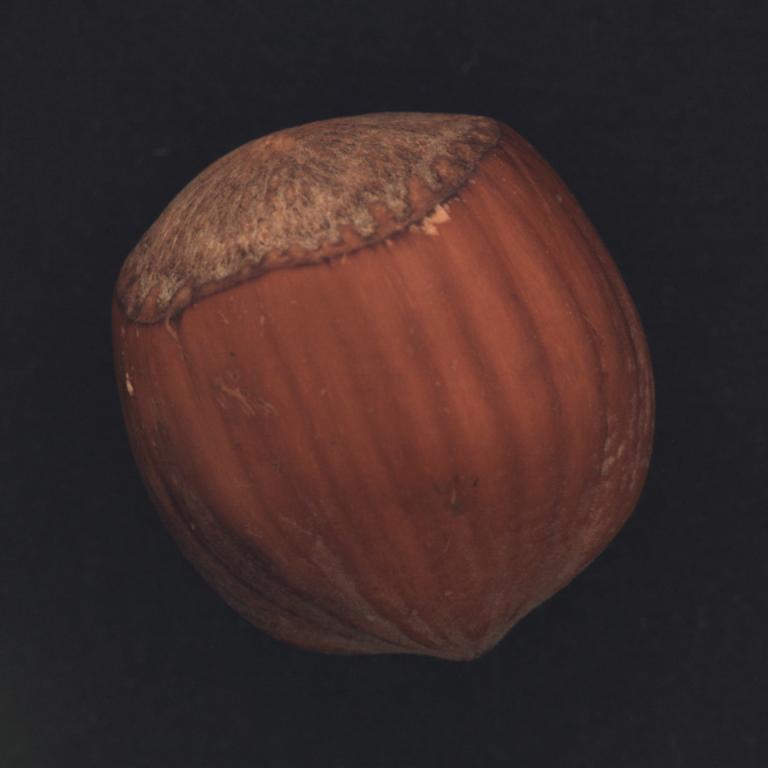

프롬프트 토큰: {0: '<|startoftext|>', 1: 'a', 2: 'photo', 3: 'of', 4: 'a', 5: 'hazelnut', 6: 'with', 7: 'a', 8: 'crack', 9: 'on', 10: 'it', 11: '<|endoftext|>'}
결함 토큰: {8: 'crack'}


In [11]:
from PIL import Image

object_name = "hazelnut"
prompt = f"a photo of a {object_name} with a crack on it"
normal_prompt = f"a photo of a {object_name}"
detailed_prompt = f"a photo of a {object_name} with a large, jagged crack exposing the interior."

image_num = str('000')
root_path = str(REPO / "example_image") + "/"
image_guidance_path = root_path + image_num + '.png'


image_guidance = Image.open(image_guidance_path).convert("RGB")
original_size = image_guidance.size
image_guidance.thumbnail((768, 768))
display(image_guidance)
tokens = token_indices_for_word(prompt, 'crack')


{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'hazelnut',
 6: 'with',
 7: 'a',
 8: 'crack',
 9: 'on',
 10: 'it'}
Altering tokens: ['crack']
hazelnut: 1/4 생성 시작 (seed=43)


  0%|          | 0/61 [00:00<?, ?it/s]

이미지 생성 진행: 0/61
이미지 생성 진행: 10/61
이미지 생성 진행: 20/61
이미지 생성 진행: 30/61
이미지 생성 진행: 40/61
이미지 생성 진행: 50/61
이미지 생성 진행: 60/61


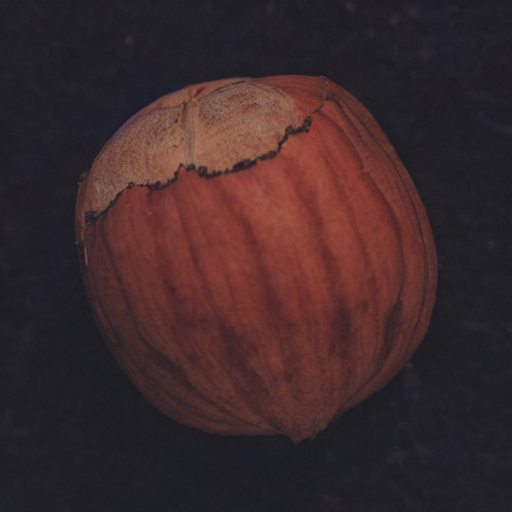

hazelnut: 생성 완료, 188.6초


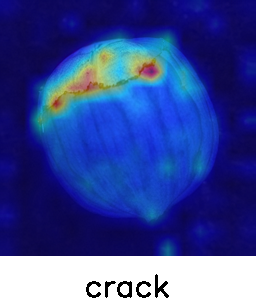

hazelnut: 2/4 생성 시작 (seed=44)


  0%|          | 0/61 [00:00<?, ?it/s]

이미지 생성 진행: 0/61
이미지 생성 진행: 10/61
이미지 생성 진행: 20/61
이미지 생성 진행: 30/61
이미지 생성 진행: 40/61
이미지 생성 진행: 50/61
이미지 생성 진행: 60/61


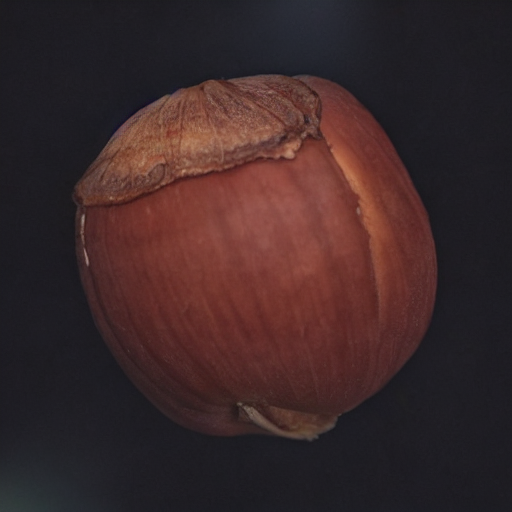

hazelnut: 생성 완료, 187.8초


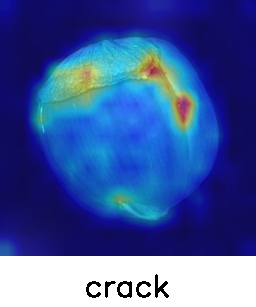

hazelnut: 3/4 생성 시작 (seed=45)


  0%|          | 0/61 [00:00<?, ?it/s]

이미지 생성 진행: 0/61
이미지 생성 진행: 10/61
이미지 생성 진행: 20/61
이미지 생성 진행: 30/61
이미지 생성 진행: 40/61
이미지 생성 진행: 50/61
이미지 생성 진행: 60/61


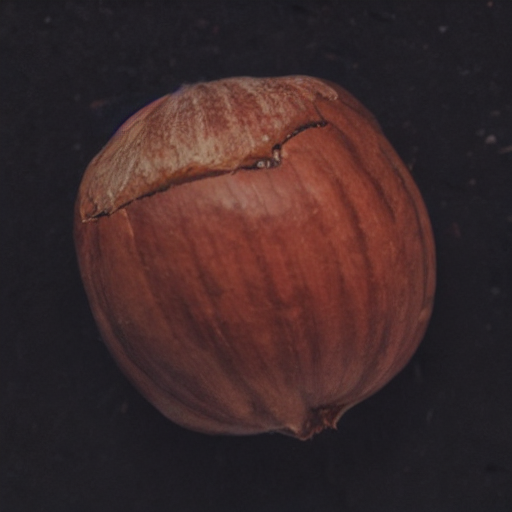

hazelnut: 생성 완료, 186.2초


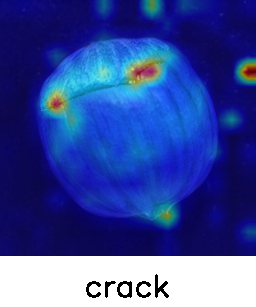

hazelnut: 4/4 생성 시작 (seed=46)


  0%|          | 0/61 [00:00<?, ?it/s]

이미지 생성 진행: 0/61
이미지 생성 진행: 10/61
이미지 생성 진행: 20/61
이미지 생성 진행: 30/61
이미지 생성 진행: 40/61
이미지 생성 진행: 50/61
이미지 생성 진행: 60/61


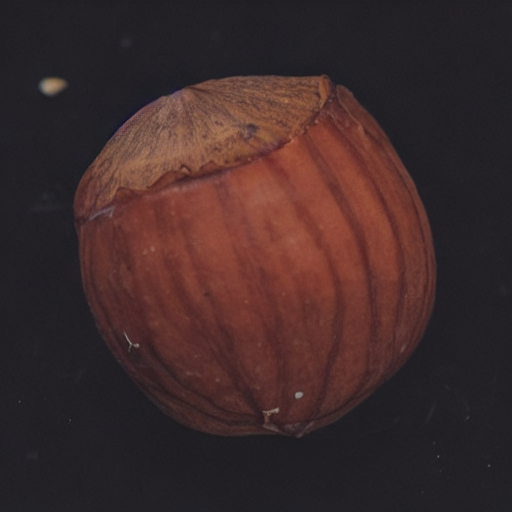

hazelnut: 생성 완료, 186.4초


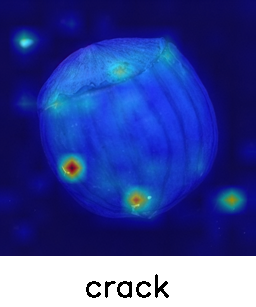

이미지 생성 셀 완료. 소요 시간(초): [188.6, 187.8, 186.2, 186.4]


In [12]:
import random
from run import get_indices_to_alter_new
import time

seeds = [43, 44, 45, 46]

token_indices = get_indices_to_alter_new(stable, prompt, tokens)


compute_time = []
for sample_number, seed in enumerate(seeds, 1):
    print(f"hazelnut: {sample_number}/{len(seeds)} 생성 시작 (seed={seed})", flush=True)
    g = torch.Generator(device=device).manual_seed(seed)
    prompts = [prompt]
    controller = AttentionStore()

    start_time = time.time()
    image, image_latent = run_and_display(prompts=prompts,
                            controller=controller,
                            indices_to_alter=token_indices,
                            # init_image=None,
                            init_image=image_guidance,
                            init_image_guidance_scale=0.3,
                            mask_image=None,   
                            generator=g,
                            run_standard_sd=False,
                            display_output=True,
                            scale_factor=50,
                            normal_prompt=normal_prompt,
                            detailed_prompt=detailed_prompt,)
    # print("--- %s seconds ---" % (time.time() - start_time))
    elapsed = time.time() - start_time
    compute_time.append(elapsed)
    image.save(RESULTS / f"hazelnut_{seed}.png")
    print(f"hazelnut: 생성 완료, {elapsed:.1f}초", flush=True)
    
    attention_images=vis_utils.show_cross_attention(attention_store=controller,
                                   prompt=prompt,
                                   tokenizer=tokenizer,
                                   res=16,
                                   from_where=("up", "down", "mid"),
                                   indices_to_alter=token_indices,
                                   orig_image=image)

    del image_latent
    gc.collect()
    torch.cuda.empty_cache()
print("이미지 생성 셀 완료. 소요 시간(초):", [round(t, 1) for t in compute_time])


## 3. PCB 균열 결함

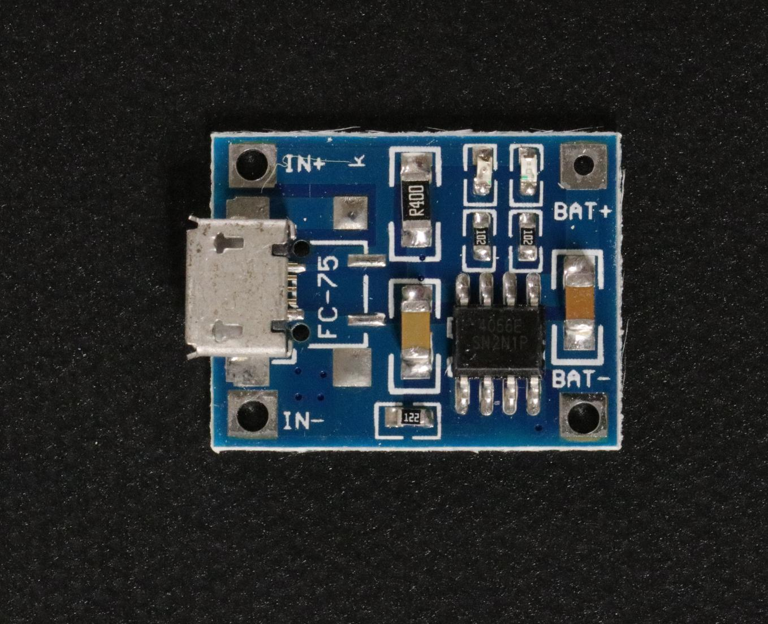

프롬프트 토큰: {0: '<|startoftext|>', 1: 'a', 2: 'photo', 3: 'of', 4: 'a', 5: 'pcb', 6: 'with', 7: 'a', 8: 'crack', 9: 'on', 10: 'it', 11: '<|endoftext|>'}
결함 토큰: {8: 'crack'}


In [13]:
from PIL import Image

object_name = "pcb"
prompt = f"a photo of a {object_name} with a crack on it"
normal_prompt = f"a photo of a {object_name}"
detailed_prompt = f"a photo of a {object_name} with a large, jagged crack exposing the interior."

image_guidance_path = str(PCB_IMAGE_PATH)


image_guidance = Image.open(image_guidance_path).convert("RGB")
original_size = image_guidance.size
image_guidance.thumbnail((768, 768))
display(image_guidance)
tokens = token_indices_for_word(prompt, 'crack')


{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'pcb',
 6: 'with',
 7: 'a',
 8: 'crack',
 9: 'on',
 10: 'it'}
Altering tokens: ['crack']
pcb: 1/4 생성 시작 (seed=47)


  0%|          | 0/61 [00:00<?, ?it/s]

이미지 생성 진행: 0/61
이미지 생성 진행: 10/61
이미지 생성 진행: 20/61
이미지 생성 진행: 30/61
이미지 생성 진행: 40/61
이미지 생성 진행: 50/61
이미지 생성 진행: 60/61


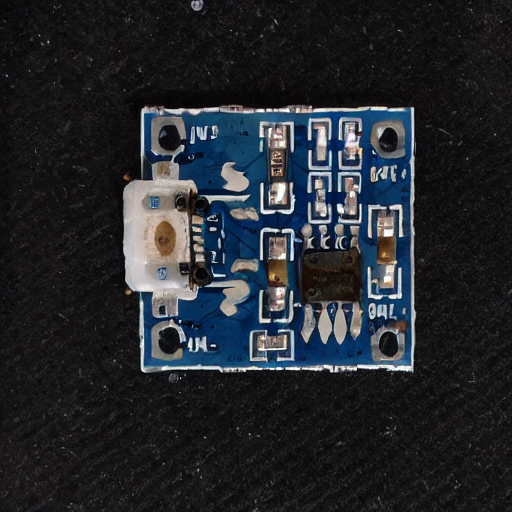

pcb: 생성 완료, 186.5초


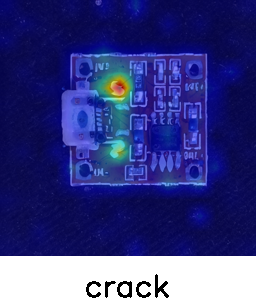

pcb: 2/4 생성 시작 (seed=48)


  0%|          | 0/61 [00:00<?, ?it/s]

이미지 생성 진행: 0/61
이미지 생성 진행: 10/61
이미지 생성 진행: 20/61
이미지 생성 진행: 30/61
이미지 생성 진행: 40/61
이미지 생성 진행: 50/61
이미지 생성 진행: 60/61


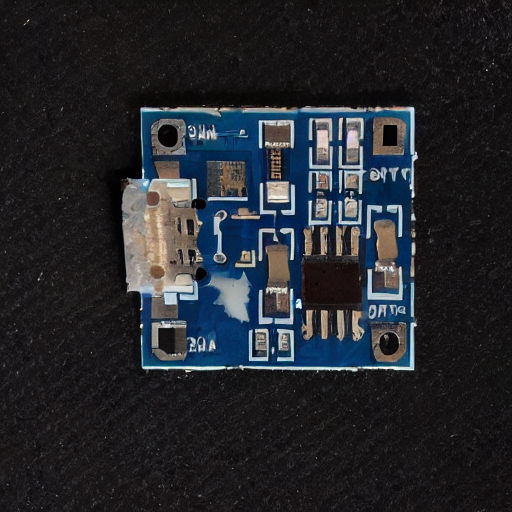

pcb: 생성 완료, 185.7초


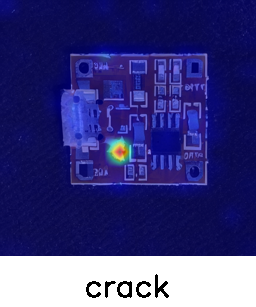

pcb: 3/4 생성 시작 (seed=49)


  0%|          | 0/61 [00:00<?, ?it/s]

이미지 생성 진행: 0/61
이미지 생성 진행: 10/61
이미지 생성 진행: 20/61
이미지 생성 진행: 30/61
이미지 생성 진행: 40/61
이미지 생성 진행: 50/61
이미지 생성 진행: 60/61


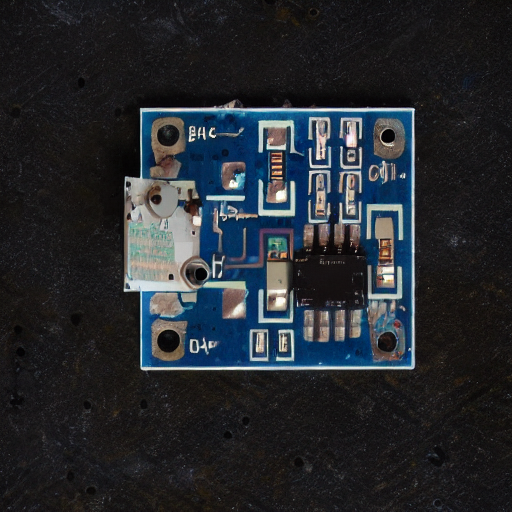

pcb: 생성 완료, 186.1초


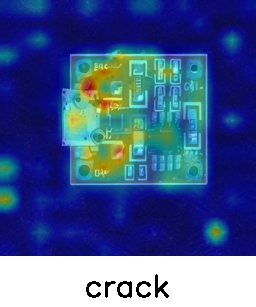

pcb: 4/4 생성 시작 (seed=50)


  0%|          | 0/61 [00:00<?, ?it/s]

이미지 생성 진행: 0/61
이미지 생성 진행: 10/61
이미지 생성 진행: 20/61
이미지 생성 진행: 30/61
이미지 생성 진행: 40/61
이미지 생성 진행: 50/61
이미지 생성 진행: 60/61


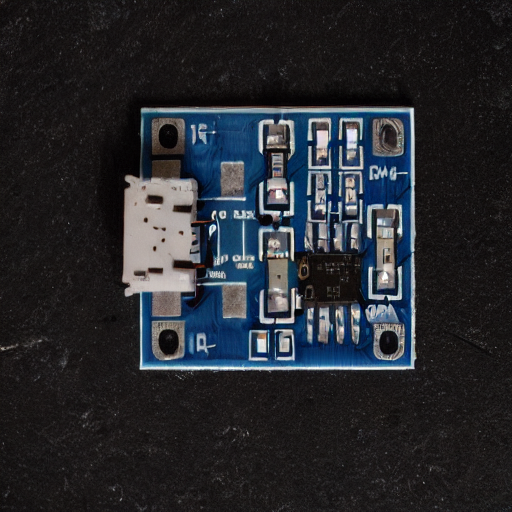

pcb: 생성 완료, 186.5초


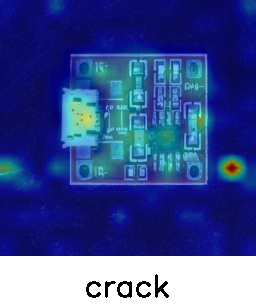

이미지 생성 셀 완료. 소요 시간(초): [186.5, 185.7, 186.1, 186.5]


In [14]:
import random
from run import get_indices_to_alter_new
import time

seeds = [47, 48, 49, 50]

token_indices = get_indices_to_alter_new(stable, prompt, tokens)


compute_time = []
for sample_number, seed in enumerate(seeds, 1):
    print(f"pcb: {sample_number}/{len(seeds)} 생성 시작 (seed={seed})", flush=True)
    g = torch.Generator(device=device).manual_seed(seed)
    prompts = [prompt]
    controller = AttentionStore()

    start_time = time.time()
    image, image_latent = run_and_display(prompts=prompts,
                            controller=controller,
                            indices_to_alter=token_indices,
                            # init_image=None,
                            init_image=image_guidance,
                            init_image_guidance_scale=0.3,
                            mask_image=None,   
                            generator=g,
                            run_standard_sd=False,
                            display_output=True,
                            scale_factor=50,
                            normal_prompt=normal_prompt,
                            detailed_prompt=detailed_prompt,)
    # print("--- %s seconds ---" % (time.time() - start_time))
    elapsed = time.time() - start_time
    compute_time.append(elapsed)
    image.save(RESULTS / f"pcb_{seed}.png")
    print(f"pcb: 생성 완료, {elapsed:.1f}초", flush=True)
    
    attention_images=vis_utils.show_cross_attention(attention_store=controller,
                                   prompt=prompt,
                                   tokenizer=tokenizer,
                                   res=16,
                                   from_where=("up", "down", "mid"),
                                   indices_to_alter=token_indices,
                                   orig_image=image)

    del image_latent
    gc.collect()
    torch.cuda.empty_cache()
print("이미지 생성 셀 완료. 소요 시간(초):", [round(t, 1) for t in compute_time])


In [ ]:
generated_files = sorted(RESULTS.glob("*.png"))
expected = {f"{name}_{seed}.png" for name, seeds in [("table", [42]), ("hazelnut", [43,44,45,46]), ("pcb", [47,48,49,50])] for seed in seeds}
assert expected.issubset({p.name for p in generated_files}), "일부 결과 이미지가 저장되지 않았습니다."
print("전체 실습 완료: 테이블 1장, 헤이즐넛 4장, PCB 4장")
print("결과 저장 폴더:", RESULTS)


전체 실습 완료: 테이블 1장, 헤이즐넛 4장, PCB 4장
결과 저장 폴더: /content/anomalyany_lab/lab_results
